# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
# El repositorio de clase no incluye wine.csv. Se usa la copia de UCI Wine
# distribuida por scikit-learn y se conserva el CSV externo antes de cargarlo.
if not DATA_PATH.exists():
    from sklearn.datasets import load_wine
    RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
    load_wine(as_frame=True).frame.to_csv(DATA_PATH, index=False)
df = pd.read_csv(DATA_PATH)
assert "target" in df and not df["target"].isna().any()
print("Fuente: UCI Wine, copia distribuida con sklearn.datasets.load_wine")
print("Archivo cargado:", DATA_PATH)

Fuente: UCI Wine, copia distribuida con sklearn.datasets.load_wine
Archivo cargado: /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_06/challenge/data/raw/wine.csv


In [4]:
print("Dimensiones:", df.shape)
print("Tipos:\n", df.dtypes)
print("Nulos:\n", df.isna().sum())
print("Duplicados:", df.duplicated().sum())
print("Distribución de target:\n", df.target.value_counts().sort_index())
assert not df.duplicated().any()
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)

Dimensiones: (178, 14)
Tipos:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object
Nulos:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_o

**Conclusión de calidad:** El archivo contiene 178 vinos, 13 características numéricas y una etiqueta de tres clases. No hay nulos ni duplicados exactos. Se conservan las observaciones; no se eliminan valores extremos sin justificación de dominio. Se incluye imputación en el pipeline para entradas futuras. El CSV faltaba en el repositorio original: su procedencia y generación quedan documentadas en la celda de carga.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(df, test_size=0.20,
    stratify=df["target"], random_state=RANDOM_STATE)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

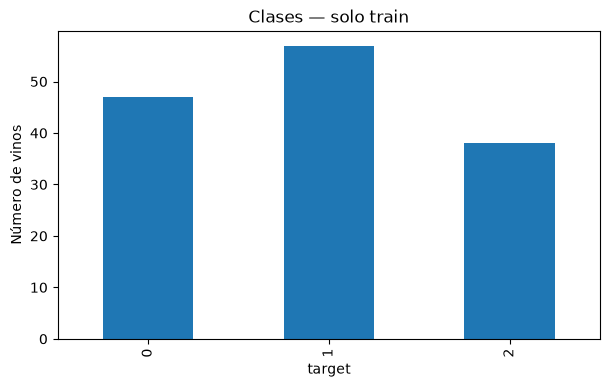

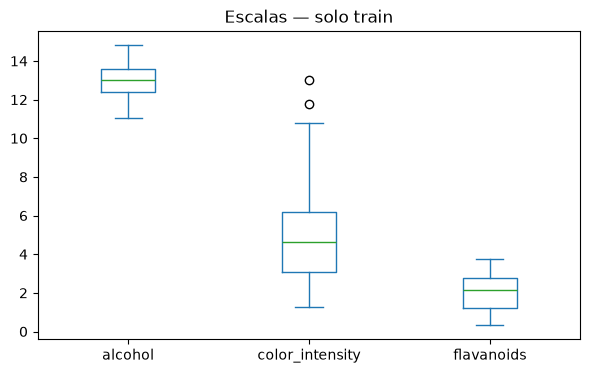

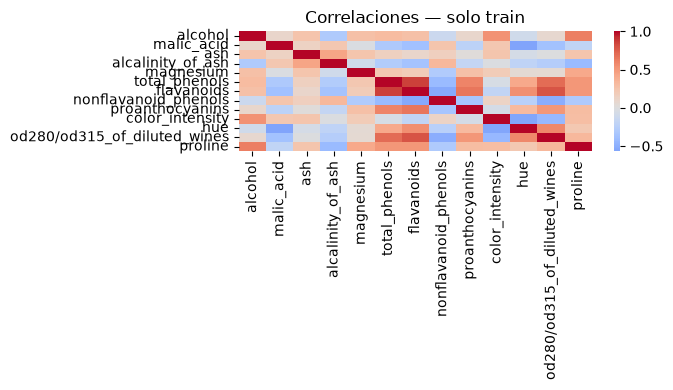

          alcohol  flavanoids      proline
target                                    
0       13.701489    2.931064  1092.340426
1       12.277368    2.011404   526.245614
2       13.109737    0.776579   622.894737
Rangos:
      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
min    11.03        0.74  1.36               10.6       70.0           0.98   
max    14.83        5.80  3.22               30.0      162.0           3.88   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
min        0.34                  0.13             0.42             1.28  0.48   
max        3.74                  0.63             3.58            13.00  1.71   

     od280/od315_of_diluted_wines  proline  
min                          1.27    278.0  
max                          3.92   1515.0  


In [7]:
train_df.target.value_counts().sort_index().plot.bar(title="Clases — solo train")
plt.ylabel("Número de vinos"); plt.show()
train_df[["alcohol", "color_intensity", "flavanoids"]].plot.box(title="Escalas — solo train")
plt.show()
sns.heatmap(train_df.drop(columns="target").corr(), cmap="coolwarm", center=0)
plt.title("Correlaciones — solo train"); plt.tight_layout(); plt.show()
print(train_df.groupby("target")[["alcohol", "flavanoids", "proline"]].mean())
print("Rangos:\n", train_df.drop(columns="target").agg(["min", "max"]))

**Hallazgos:**

1. Las escalas difieren mucho: proline está en centenas/millares y otras variables en unidades. Estandarizar es necesario para KNN y regresión logística.
2. Las clases tienen frecuencias diferentes; se conserva estratificación y se reporta F1 macro además de accuracy.
3. Flavanoids y total_phenols están positivamente correlacionados. La información redundante motiva regularización en la regresión y cautela al interpretar variables individualmente. Todo el EDA posterior al split utiliza exclusivamente entrenamiento.

## 4. Persistencia de datos y contrato

In [8]:
train_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)
contract = {"target": "target", "features": [c for c in df.columns if c != "target"],
            "random_state": RANDOM_STATE, "test_size": 0.20,
            "source": "UCI Wine via sklearn.datasets.load_wine", "classes": [0, 1, 2]}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")

442

In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.